# Linear algebra 2: Linear systems and elimination

*Learning path: linear algebra, part 2 of 9.* [Index](README.md) · Previous: [Vectors and matrices](01-vectors-and-matrices.ipynb) · Next: [Vector spaces](03-vector-spaces.ipynb)

Propane burns with oxygen into carbon dioxide and water. How many molecules of each? A circuit has five loops; what
current flows in each wire? A bridge has a hundred joints; what force does each beam carry? Each question is a set of
linear equations, sometimes millions of them, and every one is solved by the same method Gauss used to track the
asteroid Ceres in 1801: **elimination**. This lesson teaches it by hand, then shows how a computer records it as
$A = LU$.

**Who this is for.** You know vectors, matrices and matrix products ([lesson 1](01-vectors-and-matrices.ipynb)), and
have solved two equations in two unknowns at school.

**What you will be able to do afterwards:**

1. see a system $Ax = b$ in two pictures: crossing lines (rows) and combining columns;
2. solve a system by elimination and back substitution, and write each step as a matrix;
3. read the reduced row echelon form: pivots, free variables, and whether there are zero, one or infinitely many
   solutions;
4. factor $A = LU$ and use it to solve for many right-hand sides.

Plan about an hour and a half.

## 1. Two pictures of one system

Two equations in two unknowns,

$$x + 3y = 5, \qquad 2x - y = 3,$$

are one matrix equation $Ax = b$ with $A = [1\ 3;\ 2\ {-1}]$ and $b = [5;\ 3]$.

**The row picture.** Each equation is a line; the solution is where they cross. The plot shows both lines, solved for
$y$: $y = (5 - x)/3$ and $y = 2x - 3$, with $x$ across and $y$ up:

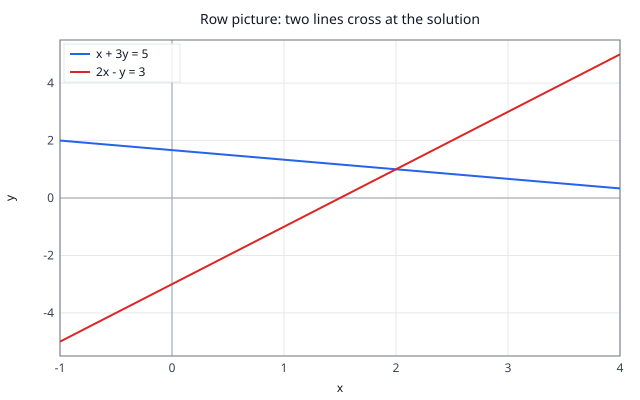

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [1]:
p = legend(plot((5 - x)/3, 2*x - 3, x, -1, 4), "x + 3y = 5", "2x - y = 3");
labels(title(p, "Row picture: two lines cross at the solution"), "x", "y")

**The column picture.** The same system says: find the numbers $x, y$ with

$$x\begin{pmatrix}1\\2\end{pmatrix} + y\begin{pmatrix}3\\-1\end{pmatrix} = \begin{pmatrix}5\\3\end{pmatrix},$$

a linear combination of the columns that lands on $b$ (lesson 1, section 3). `A\b` solves $Ax = b$ ("divide by $A$
from the left"), and `solve` works with the equations directly:

In [2]:
A = [1 3; 2 -1];
A\[5; 3]
solve([x + 3*y == 5, 2*x - y == 3], [x, y])
simplify(2*[1; 2] + 1*[3; -1])

[2;
 1]
[2, 1]

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

[5;
 3]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

The lines cross at $(2, 1)$, and indeed 2 times column 1 plus 1 times column 2 is $b$. In three unknowns the row
picture has three planes meeting in a point, which is hard to draw; the column picture still reads "combine three
columns to reach $b$", in any dimension.

**Try this.** Draw both pictures for $x + y = 2$, $x - y = 0$ in your head. Where do the lines cross, and which
combination of $[1\ 1]$ and $[1\ {-1}]$ gives $[2\ 0]$?

## 2. Elimination, step by step

Solve

$$x + y + z = 6, \qquad x - y = 0, \qquad 2x + y - z = 0.$$

Write the coefficients with the right-hand side as a last column, the **augmented matrix**. Elimination subtracts
multiples of the first row from the rows below to make zeros under the first **pivot** (the 1 in the corner), then
uses the second row to clear below the second pivot, and so on.

In [3]:
M = [1 1 1 6; 1 -1 0 0; 2 1 -1 0]

[1,  1,  1, 6;
 1, -1,  0, 0;
 2,  1, -1, 0]

Step 1: subtract 1 times row 1 from row 2. Step 2: subtract 2 times row 1 from row 3. Each step is a multiplication by
an **elimination matrix**: the identity with one extra entry, $-\ell$ in position $(i, j)$ for "subtract $\ell$ times
row $j$ from row $i$". Watch the zeros appear:

In [4]:
E21 = [1 0 0; -1 1 0; 0 0 1];
E31 = [1 0 0; 0 1 0; -2 0 1];
simplify(E31*E21*M)

[1,  1,  1,   6;
 0, -2, -1,  -6;
 0, -1, -3, -12]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

The second pivot is $-2$. To clear the $-1$ below it, subtract $\tfrac12$ times row 2 from row 3:

In [5]:
E32 = [1 0 0; 0 1 0; 0 -1/2 1];
U = simplify(E32*E31*E21*M)

[1,  1,    1,  6;
 0, -2,   -1, -6;
 0,  0, -5/2, -9]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

Now the system is **upper triangular**:

$$x + y + z = 6, \qquad -2y - z = -6, \qquad -\tfrac52 z = -9,$$

and **back substitution** solves it from the bottom up: $z = 18/5$, then $-2y = -6 + 18/5$ gives $y = 6/5$, then
$x = 6 - 6/5 - 18/5 = 6/5$.

In [6]:
solve([x + y + z == 6, x - y == 0, 2*x + y - z == 0], [x, y, z])

[6/5, 6/5, 18/5]

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

Elimination fails only if a pivot is 0. Sometimes a **row exchange** fixes that (swap with a lower row that has a
nonzero entry in that column); if no row can help, the matrix is **singular**, and the next section says what happens.

**Try this.** Eliminate by hand: $2x + y = 4$, $6x + 5y = 16$. What is the multiplier, the second pivot, and the
solution?

## 3. Reduced row echelon form: zero, one or infinitely many solutions

Keep going after elimination: divide each row by its pivot and clear *above* the pivots too. The result is the
**reduced row echelon form**, `rref`, where the solution can be read off:

In [7]:
rref(M)

[1, 0, 0,  6/5;
 0, 1, 0,  6/5;
 0, 0, 1, 18/5]

> `rref`: Row reduction: rref is the reduced row echelon form, rank the number of independent rows, null a basis of the solutions of A*x = 0 (one vector per column; empty when x = 0 is the only solution).

Row by row: $x = 6/5$, $y = 6/5$, $z = 18/5$. One solution.

Now change the third equation to $2x + 2y + 2z = 12$, which is just twice the first:

In [8]:
N = [1 1 1; 1 -1 0; 2 2 2];
rref([N, [6; 0; 12]])
solve([x + y + z == 6, x - y == 0, 2*x + 2*y + 2*z == 12], [x, y, z])

[1, 0, 1/2, 3;
 0, 1, 1/2, 3;
 0, 0,   0, 0]

> `rref`: Row reduction: rref is the reduced row echelon form, rank the number of independent rows, null a basis of the solutions of A*x = 0 (one vector per column; empty when x = 0 is the only solution).

[3-z/2, 3-z/2, z]

> Infinitely many solutions: z is free (any value works) and the other unknowns are given in terms of it. Elimination left 2 independent equation(s) for 3 unknowns.

The last row is all zeros: the third equation said nothing new. Only two columns have pivots, so one unknown, $z$, is
**free**: choose any value, and the pivot rows give $x = 3 - z/2$ and $y = 3 - z/2$. Infinitely many solutions, a
line of them in space. `solve` returns them with $z$ left as a symbol.

If the third right-hand side were 13 instead of 12, the last row would read $0 = 1$: no solution at all. The planes
do not have a common point.

In [9]:
rref([N, [6; 0; 13]])

[1, 0, 1/2, 0;
 0, 1, 1/2, 0;
 0, 0,   0, 1]

> `rref`: Row reduction: rref is the reduced row echelon form, rank the number of independent rows, null a basis of the solutions of A*x = 0 (one vector per column; empty when x = 0 is the only solution).

In general, for an augmented matrix in reduced form:

* a row $[0\ 0\ \cdots\ 0 \mid 1]$ means **no solution**;
* otherwise, every column without a pivot is a **free variable**: no free variables means **exactly one solution**,
  free variables mean **infinitely many**.

The number of pivots is the **rank** (`rank`). It counts the equations that really say something.

**Try this.** Without solving, decide how many solutions $x + 2y = 3$, $2x + 4y = 6$ has, and how many
$x + 2y = 3$, $2x + 4y = 7$ has.

## 4. Homogeneous systems: balancing a chemical equation

When $b = 0$, the system $Ax = 0$ always has the solution $x = 0$. The interesting question is whether there are
others: the **null space** of $A$, `null(A)`.

Propane, $\text{C}_3\text{H}_8$, burns: $a\,\text{C}_3\text{H}_8 + b\,\text{O}_2 \to c\,\text{CO}_2 + d\,\text{H}_2\text{O}$.
Count atoms on both sides: carbon $3a = c$, hydrogen $8a = 2d$, oxygen $2b = 2c + d$. Move everything to the left:

In [10]:
C = [3 0 -1 0; 8 0 0 -2; 0 2 -2 -1];
null(C)

[1/4;
 5/4;
 3/4;
   1]

> `null` (see `rref`): Row reduction: rref is the reduced row echelon form, rank the number of independent rows, null a basis of the solutions of A*x = 0 (one vector per column; empty when x = 0 is the only solution).

Three equations, four unknowns, so at least one free variable: the null space is the line through
$[1/4\ \ 5/4\ \ 3/4\ \ 1]$. Multiply by 4 for whole molecules:

$$\text{C}_3\text{H}_8 + 5\,\text{O}_2 \to 3\,\text{CO}_2 + 4\,\text{H}_2\text{O}.$$

The general principle: **every solution of $Ax = b$ is one particular solution plus a solution of $Ax = 0$.** If
$Ax_p = b$ and $Ax_n = 0$, then $A(x_p + x_n) = b$; and the difference of two solutions solves $Ax = 0$. In section 3
the line of solutions was $[3\ 3\ 0] + z\,[-1/2\ \ {-1/2}\ \ 1]$: a particular point plus the null space of $N$.

In [11]:
null(N)

[-1/2;
 -1/2;
    1]

> `null` (see `rref`): Row reduction: rref is the reduced row echelon form, rank the number of independent rows, null a basis of the solutions of A*x = 0 (one vector per column; empty when x = 0 is the only solution).

**Try this.** Balance $a\,\text{H}_2 + b\,\text{O}_2 \to c\,\text{H}_2\text{O}$ the same way.

## 5. Elimination as a factorization: $A = LU$

In section 2 we found $E_{32}E_{31}E_{21}A = U$. Undo the steps: $A = (E_{32}E_{31}E_{21})^{-1}U = LU$, where $L$ is
**lower triangular** with ones on the diagonal and the **multipliers** $\ell_{ij}$ below it. Nothing to compute: the
numbers you subtracted with are stored in $L$.

`[L, U, P] = lu(A)` factors $PA = LU$; $P$ records row exchanges. (Galileo, like every numerical library, exchanges
rows to use the largest available pivot, which keeps rounding errors small. For this matrix no exchange is needed, so
$P = I$.)

In [12]:
A = [2 1 0; 1 2 1; 0 1 2];
[L, U, P] = lu(A)
simplify(L*U)

L = [  1,   0, 0;
 1/2,   1, 0;
   0, 2/3, 1]
U = [2,   1,   0;
 0, 3/2,   1;
 0,   0, 4/3]
P = [1, 0, 0;
 0, 1, 0;
 0, 0, 1]
[2, 1, 0;
 1, 2, 1;
 0, 1, 2]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

The multipliers are $\ell_{21} = 1/2$ (row 2 minus half of row 1) and $\ell_{32} = 2/3$; $\ell_{31} = 0$ because row 3
already had a 0. Why bother? Solving $Ax = b$ becomes two triangular solves: first $Lc = b$ (forward), then $Ux = c$
(backward). Elimination costs about $n^3/3$ operations for an $n\times n$ matrix; each triangular solve only about
$n^2$. With $L$ and $U$ stored, a new right-hand side is cheap, which matters when the same structure (a bridge, a
circuit) meets many different loads.

In [13]:
b = [1; 2; 3];
c = L\b
U\c
A\b

[  1;
 3/2;
   2]
[1/2;
   0;
 3/2]
[1/2;
   0;
 3/2]

**Try this.** Factor $A = [2\ 1;\ 6\ 5]$ by hand (the system from the Try this of section 2). What are $L$ and $U$?
Check with `lu`.

## Exercises

1. **Three cases.** For which $k$ does $x + y = 1$, $x + ky = 1$ have exactly one solution? For which $k$ infinitely
   many? Can it ever have none?
2. **Elimination matrices.** Find the elimination matrix that subtracts 3 times row 1 from row 2 of a $3\times3$
   matrix, and its inverse. Why is the inverse "add 3 times row 1 to row 2"?
3. **Free variables.** Find all solutions of $x + 2y + 3z = 0$, $4x + 5y + 6z = 0$, $7x + 8y + 9z = 0$. What is the
   rank of the matrix?
4. **Balance.** Balance $a\,\text{Fe} + b\,\text{O}_2 \to c\,\text{Fe}_2\text{O}_3$ (rust).
5. **LU.** Factor $A = [1\ 1\ 1;\ 1\ 2\ 2;\ 1\ 2\ 3]$ as $LU$ by hand. Then use it to solve $Ax = [1\ 0\ 0]$.

## Hints and answers

* **Section 1, Try this.** The lines cross at $(1, 1)$, and $1\cdot[1\ 1] + 1\cdot[1\ {-1}] = [2\ 0]$.
* **Section 2, Try this.** Multiplier 3; second pivot $5 - 3 = 2$; $2y = 16 - 12 = 4$, $y = 2$, $x = 1$.
* **Section 3, Try this.** The second equation of the first pair is twice the first: infinitely many. In the second
  pair elimination gives $0 = 1$: none.
* **Section 4, Try this.** H: $2a = 2c$, O: $2b = c$; `null([2 0 -2; 0 2 -1])` is $[1\ \ 1/2\ \ 1]$, so
  $2\,\text{H}_2 + \text{O}_2 \to 2\,\text{H}_2\text{O}$.
* **Section 5, Try this.** $L = [1\ 0;\ 3\ 1]$, $U = [2\ 1;\ 0\ 2]$. (`lu` exchanges the rows here because 6 is the
  larger pivot, so it reports a different, equally valid, factorization $PA = LU$.)
* **Exercise 1.** Elimination gives $(k - 1)y = 0$: one solution when $k \ne 1$; for $k = 1$ both equations are the
  same, infinitely many. Never none: $(1, 0)$ solves both
  equations for every $k$.
* **Exercise 2.** $E = [1\ 0\ 0;\ {-3}\ 1\ 0;\ 0\ 0\ 1]$, $E^{-1} = [1\ 0\ 0;\ 3\ 1\ 0;\ 0\ 0\ 1]$: to undo a
  subtraction, add back.
* **Exercise 3.** `solve(...)` gives $[z,\ -2z,\ z]$: the line through $[1\ {-2}\ 1]$. Rank 2.
* **Exercise 4.** Fe: $a = 2c$, O: $2b = 3c$. `null([1 0 -2; 0 2 -3])` is $[2\ \ 3/2\ \ 1]$, so
  $4\,\text{Fe} + 3\,\text{O}_2 \to 2\,\text{Fe}_2\text{O}_3$.
* **Exercise 5.** $L = [1\ 0\ 0;\ 1\ 1\ 0;\ 1\ 1\ 1]$, $U = [1\ 1\ 1;\ 0\ 1\ 1;\ 0\ 0\ 1]$; $Lc = b$ gives
  $c = [1\ {-1}\ 0]$, $Ux = c$ gives $x = [2\ {-1}\ 0]$. Check: `[1 1 1; 1 2 2; 1 2 3]\[1; 0; 0]`.

## Sources

1. G. Strang, *Introduction to Linear Algebra*, 6th ed., Wellesley-Cambridge Press (2023), chapter 2.
2. D. C. Lay, S. R. Lay and J. J. McDonald, *Linear Algebra and Its Applications*, 6th ed., Pearson (2021), sections
   1.1 to 1.6 and 2.5.
3. C. F. Gauss, *Theoria motus corporum coelestium* (1809): elimination for fitting the orbit of Ceres.
4. L. N. Trefethen and D. Bau, *Numerical Linear Algebra*, SIAM (1997), lectures 20 to 22 (LU and pivoting).